# EDA-02 Missing & Continuous Vars

## Pomysły

1) HistGradientBoostingClassifier - toleruje braki - model bazowy?
2) Podzielić zmienne na grupy braków 0-5%, 5-20%, 20-40%, 40-60%, 60-80%, 80-100%
3) Sprawdzić naiwną eliminację kolumn powyżej pewnego Threshold-u. Może tak jak grupy wyżej
4) Sprawdzić naiwną imputację medianową, średnią
5) Sprawdzić jak sprawdzi się usunięcie kolumn które korelują z innymi nieposiadającymi tylu braków
6) Czy jest imputer który korzysta z korelacji pomiędzy kolumnami do dedukcji prawdopodobnej wartości braku?
7) Czy występuje jakiś pattern pomiędzy brakami a zmienną celu?

In [1]:
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

from secomml.data_loader import load_secom
from secomml.data_eda import profile
from secomml.data_convert_types import convert_pass_to_boolean
from secomml.data_cleaning import drop_zero_variance_columns

sys.path.extend(['../src'])

In [15]:
df = load_secom("../data/raw/secom.zip").drop(columns=['timestamp'])
df = convert_pass_to_boolean(df)
df = drop_zero_variance_columns(df)
n  = df.shape[0]
df

,pass,x0,x1,x2,x3,x4,x6,x7,x8,x9,...,x580,x581,x582,x583,x584,x585,x586,x587,x588,x589
0,True,3030.93,2564.0,2187.7333,1411.1265,1.3602,97.6133,0.1242,1.5005,0.0162,...,<NA>,<NA>,0.5005,0.0118,0.0035,2.363,<NA>,<NA>,<NA>,<NA>
1,True,3095.78,2465.14,2230.4222,1463.6606,0.8294,102.3433,0.1247,1.4966,-0.0005,...,0.006,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.006,208.2045
2,False,2932.61,2559.94,2186.4111,1698.0172,1.5102,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,True,2988.72,2479.9,2199.0333,909.7926,1.3204,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.499,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,True,3032.24,2502.87,2233.3667,1326.52,1.5334,100.3967,0.1235,1.5031,-0.0031,...,<NA>,<NA>,0.48,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1562,True,2899.41,2464.36,2179.7333,3085.3781,1.4843,82.2467,0.1248,1.3424,-0.0045,...,0.0047,203.172,0.4988,0.0143,0.0039,2.8669,0.0068,0.0138,0.0047,203.172
1563,True,3052.31,2522.55,2198.5667,1124.6595,0.8763,98.4689,0.1205,1.4333,-0.0061,...,<NA>,<NA>,0.4975,0.0131,0.0036,2.6238,0.0068,0.0138,0.0047,203.172
1564,True,2978.81,2379.78,2206.3,1110.4967,0.8236,99.4122,0.1208,<NA>,<NA>,...,0.0025,43.5231,0.4987,0.0153,0.0041,3.059,0.0197,0.0086,0.0025,43.5231
1565,True,2894.92,2532.01,2177.0333,1183.7287,1.5726,98.7978,0.1213,1.4622,-0.0072,...,0.0075,93.4941,0.5004,0.0178,0.0038,3.5662,0.0262,0.0245,0.0075,93.4941


In [ ]:
# run the processing done in eda01.ipynb

## Missing

### Variables distribution in perspective of missing values quantity

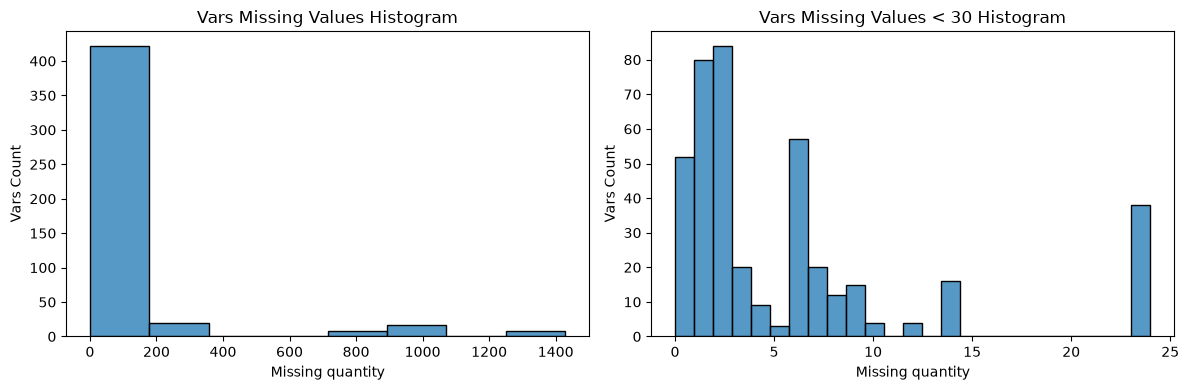

In [109]:
missing = df.drop(columns='pass').isna().sum()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
sns.histplot(data=missing, ax=ax[0], bins=8)
ax[0].set(title="Vars Missing Values Histogram", xlabel="Missing quantity", ylabel="Vars Count")
sns.histplot(data=missing[missing < 30], ax=ax[1], bins=25)
ax[1].set(title="Vars Missing Values < 30 Histogram", xlabel="Missing quantity", ylabel="Vars Count")
plt.tight_layout()
plt.show()

In [111]:
a = missing.quantile(np.concat([np.linspace(0,0.9,10), np.linspace(0.91,1,10)])).round(1)
a.index = np.round(a.index,2)
a

0.00       0.0
0.10       0.0
0.20       1.0
0.30       2.0
0.40       2.0
0.50       4.0
0.60       6.0
0.70       8.0
0.80      24.0
0.90     260.0
0.91     260.0
0.92     273.0
0.93     273.0
0.94     715.0
0.95     848.3
0.96    1018.0
0.97    1018.0
0.98    1018.0
0.99    1341.0
1.00    1429.0
dtype: float64

AttributeError: 'Figure' object has no attribute 'sharey'

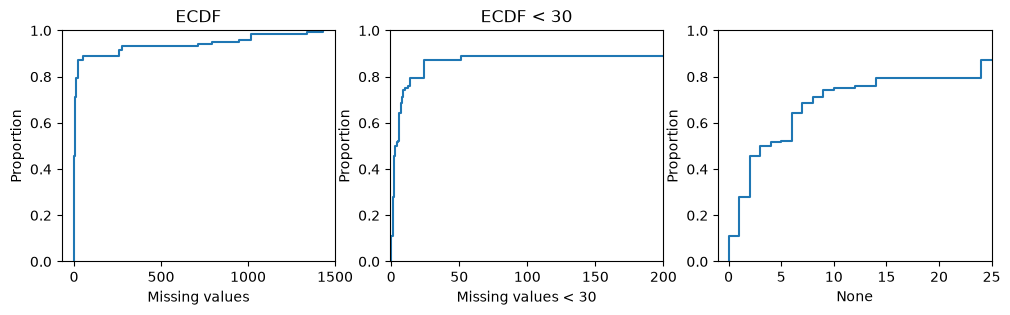

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12, 3))
sns.ecdfplot(x=missing, ax=ax[0])
sns.ecdfplot(x=missing, ax=ax[1])
sns.ecdfplot(x=missing, ax=ax[2])
ax[1].set_xlim(-1, 200)
ax[2].set_xlim(-1, 25)

ax[0].set(title='ECDF', xlabel="Missing values")
ax[1].set(title='ECDF < 30', xlabel="Missing values < 30")
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12, 3), sharey=True)
sns.ecdfplot(x=missing, ax=ax[0])
sns.ecdfplot(x=missing, ax=ax[1])
sns.ecdfplot(x=missing, ax=ax[2])
ax[1].set_xlim(-1, 200)
ax[2].set_xlim(-1, 25)

ax[0].set(title='ECDF', xlabel="Missing values")
ax[1].set(title='ECDF < 30', xlabel="Missing values < 30")
ax[2].set(title='ECDF < 25', xlabel="Missing values < 25")

plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()
plt.show()

### Split vars to group in criterium of missing quantity

In [95]:
missing_bins = pd.qcut(missing, q=10, duplicates='drop')
missing_bins

x0         (4.0, 6.0]
x1         (6.0, 8.0]
x2        (8.0, 24.0]
x3        (8.0, 24.0]
x4        (8.0, 24.0]
            ...      
x585    (-0.001, 1.0]
x586    (-0.001, 1.0]
x587    (-0.001, 1.0]
x588    (-0.001, 1.0]
x589    (-0.001, 1.0]
Length: 474, dtype: category
Categories (8, interval[float64, right]): [(-0.001, 1.0] < (1.0, 2.0] < (2.0, 4.0] < (4.0, 6.0] < (6.0, 8.0] < (8.0, 24.0] < (24.0, 260.0] < (260.0, 1429.0]]

In [96]:
missing_bins = pd.qcut(missing, q=10, duplicates='drop')
missing_bins.value_counts().sort_index()

(-0.001, 1.0]      132
(1.0, 2.0]          84
(2.0, 4.0]          29
(4.0, 6.0]          60
(6.0, 8.0]          32
(8.0, 24.0]         77
(24.0, 260.0]       20
(260.0, 1429.0]     40
Name: count, dtype: int64

In [97]:
missing_bins_perc = pd.qcut(missing / n * 100, q=10, duplicates='drop')
missing_bins_perc.value_counts().sort_index()

(-0.001, 0.0638]    132
(0.0638, 0.128]      84
(0.128, 0.255]       29
(0.255, 0.383]       60
(0.383, 0.511]       32
(0.511, 1.532]       77
(1.532, 16.592]      20
(16.592, 91.193]     40
Name: count, dtype: int64

In [98]:
bins = pd.IntervalIndex.from_tuples([(-1,0), (0, 5), (5, 20), (20, 40), (40, 60), (60, 80), (80, 100)])
pd.cut(missing / n * 100, bins=bins)

x0      (0, 5]
x1      (0, 5]
x2      (0, 5]
x3      (0, 5]
x4      (0, 5]
         ...  
x585    (0, 5]
x586    (0, 5]
x587    (0, 5]
x588    (0, 5]
x589    (0, 5]
Length: 474, dtype: category
Categories (7, interval[int64, right]): [(-1, 0] < (0, 5] < (5, 20] < (20, 40] < (40, 60] < (60, 80] < (80, 100]]

In [99]:
# CDF

In [100]:
df_grby_pass = df.groupby('pass').agg(lambda x: pd.isna(x).sum())
df_grby_pass.T

pass,False,True
x0,0,6
x1,1,6
x2,0,14
x3,0,14
x4,0,14
...,...,...
x585,0,1
x586,0,1
x587,0,1
x588,0,1


<Axes: xlabel='pass'>

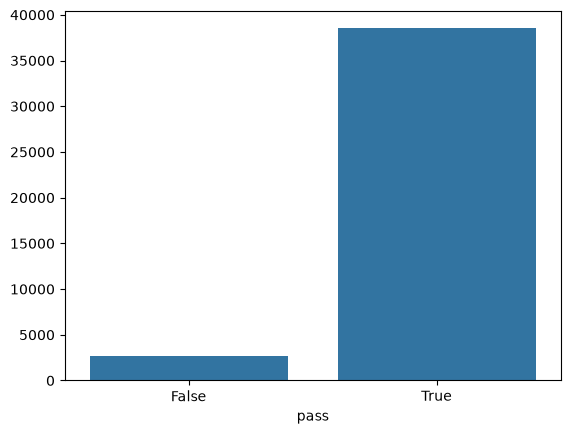

In [101]:
sns.barplot(data=df_grby_pass.T.sum())

In [102]:
df.isna().sum() / n

pass    0.000000
x0      0.003829
x1      0.004467
x2      0.008934
x3      0.008934
          ...   
x585    0.000638
x586    0.000638
x587    0.000638
x588    0.000638
x589    0.000638
Length: 475, dtype: float64